# Train and evaluate (Kaggle, GPU)

Trains three variants with identical data, schedule and loss:

| Variant | Encoder | Initialisation |
|---|---|---|
| v1_r34_scratch | ResNet-34 | random |
| v2_r50_imagenet | ResNet-50 | ImageNet |
| v3_r50_ssl4eo_s1 | ResNet-50 | SSL4EO-S12 Sentinel-1 (self-supervised) |

Round 2 adds 3-month input (`_t3`: months t-1, t, t+1 -> map for month t) and 32 training regions.

In [1]:
import glob, os, shutil, subprocess, sys
from pathlib import Path
DATA = Path(glob.glob("/kaggle/input/**/meta.json", recursive=True)[0]).parent
print("dataset:", DATA)

REPO = Path("/kaggle/working/s1lulc-repo")
if not REPO.exists():
    zips = glob.glob("/kaggle/input/**/s1lulc-repo.zip", recursive=True)
    if zips:
        subprocess.run(["unzip", "-q", "-o", zips[0], "-d", "/kaggle/working"], check=True)
    else:   # Kaggle extracted the zip on upload
        src = [p for p in glob.glob("/kaggle/input/**/pyproject.toml", recursive=True)
               if (Path(p).parent / "s1lulc").is_dir()][0]
        shutil.copytree(Path(src).parent, REPO)
!pip -q install -e /kaggle/working/s1lulc-repo segmentation-models-pytorch
sys.path.insert(0, str(REPO))

dataset: /kaggle/input/datasets/mofi007/s1lulc-dataset
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for s1lulc (pyproject.toml) ... done


In [2]:
   import json; print(sum(r["split"] == "train" for r in json.load(open(DATA / "meta.json"))["regions"]))

32


In [3]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
import torch, logging
print("torch", torch.__version__, "cuda", torch.cuda.is_available())
logging.basicConfig(level=logging.INFO, stream=sys.stdout, force=True,
                    format="%(asctime)s %(levelname)s %(message)s")

name, memory.total [MiB]
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB
torch 2.11.0+cu130 cuda True


## Training

training regions in this dataset version: 32
============================== v1_r34_scratch_32reg ==============================
2026-11-08 08:07:02,436 INFO v1_r34_scratch_32reg: 32 train / 4 val regions on cuda
2026-11-08 08:07:02,588 INFO rare classes (oversampled): ['bare_sparse', 'wetland']
2026-11-08 08:07:03,290 INFO model unet/resnet34 init=None, input 1 months (2 channels), 24.4M parameters
2026-11-08 08:07:43,867 INFO epoch   1/50  loss 2.1859  acc 0.497 | val mIoU 0.3198 OA 0.480 NLL 1.287 * (40s)
2026-11-08 08:08:19,284 INFO epoch   2/50  loss 1.6907  acc 0.630 | val mIoU 0.3577 OA 0.538 NLL 1.383 * (35s)
2026-11-08 08:08:55,804 INFO epoch   3/50  loss 1.6387  acc 0.643 | val mIoU 0.3532 OA 0.501 NLL 1.338   (36s)
2026-11-08 08:09:34,048 INFO epoch   4/50  loss 1.5908  acc 0.653 | val mIoU 0.3641 OA 0.542 NLL 1.219 * (38s)
2026-11-08 08:10:12,998 INFO epoch   5/50  loss 1.5404  acc 0.662 | val mIoU 0.3432 OA 0.513 NLL 1.317   (39s)
2026-11-08 08:10:51,316 INFO epoch   6/50  

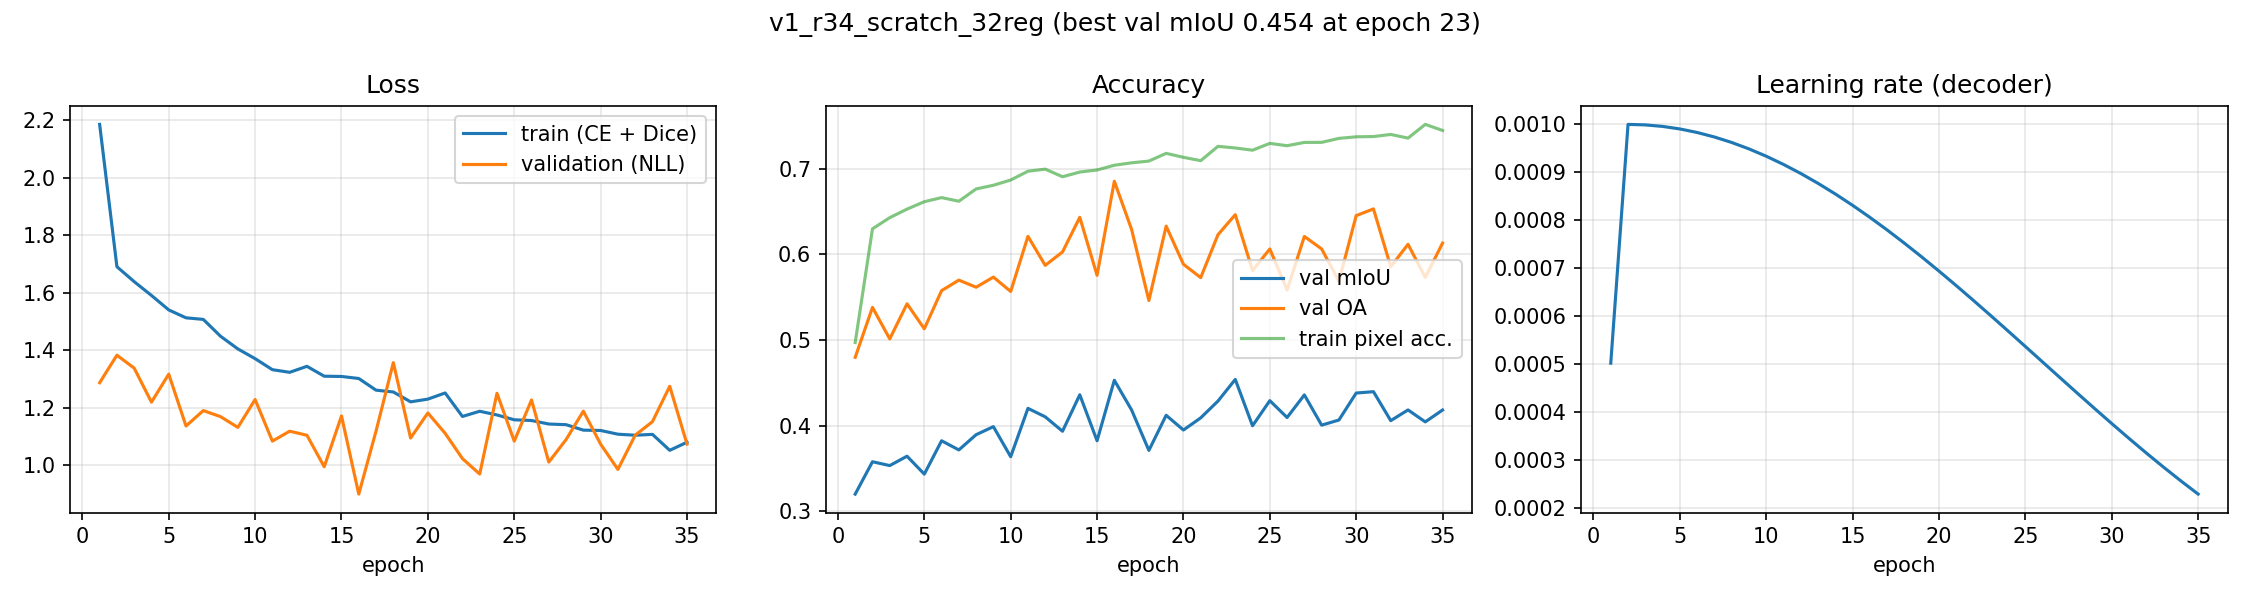

============================== v2_r50_imagenet_32reg ==============================
2026-11-08 08:29:41,411 INFO v2_r50_imagenet_32reg: 32 train / 4 val regions on cuda
2026-11-08 08:29:41,552 INFO rare classes (oversampled): ['bare_sparse', 'wetland']
2026-11-08 08:29:42,011 INFO HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
2026-11-08 08:29:42,072 INFO HTTP Request: HEAD https://huggingface.co/smp-hub/resnet50.imagenet/resolve/00cb74e366966d59cd9a35af57e618af9f88efe9/config.json "HTTP/1.1 307 Temporary Redirect"


2026-11-08 08:29:42,073 WARNING Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
2026-11-08 08:29:42,089 INFO HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/smp-hub/resnet50.imagenet/00cb74e366966d59cd9a35af57e618af9f88efe9/config.json?%2Fsmp-hub%2Fresnet50.imagenet%2Fresolve%2F00cb74e366966d59cd9a35af57e618af9f88efe9%2Fconfig.json=&etag=%22879c59b3870194ae248b52920479fed460415e62%22 "HTTP/1.1 200 OK"
2026-11-08 08:29:42,108 INFO HTTP Request: GET https://huggingface.co/api/resolve-cache/models/smp-hub/resnet50.imagenet/00cb74e366966d59cd9a35af57e618af9f88efe9/config.json?%2Fsmp-hub%2Fresnet50.imagenet%2Fresolve%2F00cb74e366966d59cd9a35af57e618af9f88efe9%2Fconfig.json=&etag=%22879c59b3870194ae248b52920479fed460415e62%22 "HTTP/1.1 200 OK"


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

2026-11-08 08:29:42,185 INFO HTTP Request: HEAD https://huggingface.co/smp-hub/resnet50.imagenet/resolve/00cb74e366966d59cd9a35af57e618af9f88efe9/model.safetensors "HTTP/1.1 302 Found"
2026-11-08 08:29:42,325 INFO HTTP Request: GET https://huggingface.co/api/models/smp-hub/resnet50.imagenet/xet-read-token/00cb74e366966d59cd9a35af57e618af9f88efe9 "HTTP/1.1 200 OK"


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

2026-11-08 08:29:44,286 INFO model unet/resnet50 init=imagenet, input 1 months (2 channels), 32.5M parameters
2026-11-08 08:30:35,272 INFO epoch   1/50  loss 1.9574  acc 0.555 | val mIoU 0.3415 OA 0.477 NLL 1.542 * (51s)
2026-11-08 08:31:24,358 INFO epoch   2/50  loss 1.3614  acc 0.692 | val mIoU 0.4067 OA 0.581 NLL 1.284 * (49s)
2026-11-08 08:32:14,199 INFO epoch   3/50  loss 1.2495  acc 0.723 | val mIoU 0.4054 OA 0.559 NLL 1.245   (49s)
2026-11-08 08:33:03,413 INFO epoch   4/50  loss 1.1409  acc 0.742 | val mIoU 0.3836 OA 0.555 NLL 1.398   (49s)
2026-11-08 08:33:52,999 INFO epoch   5/50  loss 1.0773  acc 0.757 | val mIoU 0.4066 OA 0.568 NLL 1.243   (49s)
2026-11-08 08:34:42,489 INFO epoch   6/50  loss 1.0564  acc 0.761 | val mIoU 0.4300 OA 0.601 NLL 1.079 * (49s)
2026-11-08 08:35:32,001 INFO epoch   7/50  loss 1.0566  acc 0.759 | val mIoU 0.4117 OA 0.589 NLL 1.204   (49s)
2026-11-08 08:36:21,442 INFO epoch   8/50  loss 0.9797  acc 0.774 | val mIoU 0.4290 OA 0.595 NLL 1.161   (49s)
20

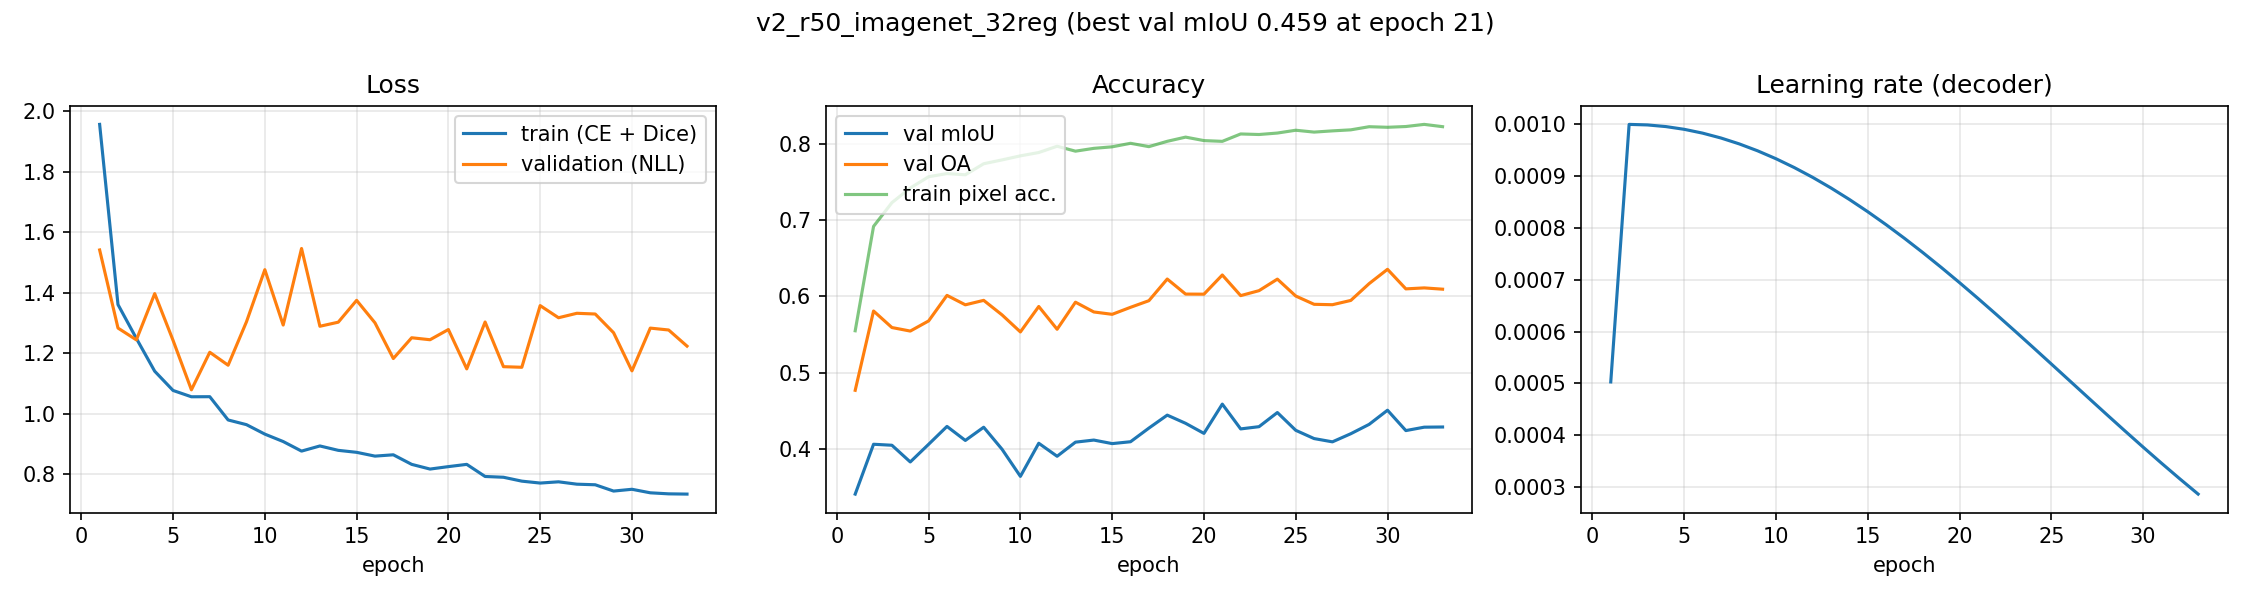

============================== v4_r34_scratch_t3_32reg ==============================
2026-11-08 08:57:13,154 INFO v4_r34_scratch_t3_32reg: 32 train / 4 val regions on cuda
2026-11-08 08:57:13,301 INFO rare classes (oversampled): ['bare_sparse', 'wetland']
2026-11-08 08:57:13,665 INFO model unet/resnet34 init=None, input 3 months (6 channels), 24.4M parameters
2026-11-08 08:57:56,032 INFO epoch   1/50  loss 2.0578  acc 0.536 | val mIoU 0.3323 OA 0.476 NLL 1.298 * (42s)
2026-11-08 08:58:38,590 INFO epoch   2/50  loss 1.6090  acc 0.653 | val mIoU 0.3647 OA 0.560 NLL 1.312 * (42s)
2026-11-08 08:59:20,846 INFO epoch   3/50  loss 1.5499  acc 0.663 | val mIoU 0.3463 OA 0.498 NLL 1.327   (42s)
2026-11-08 09:00:03,638 INFO epoch   4/50  loss 1.5053  acc 0.674 | val mIoU 0.3733 OA 0.566 NLL 1.205 * (42s)
2026-11-08 09:00:45,849 INFO epoch   5/50  loss 1.4642  acc 0.683 | val mIoU 0.3845 OA 0.574 NLL 1.120 * (42s)
2026-11-08 09:01:28,438 INFO epoch   6/50  loss 1.4236  acc 0.689 | val mIoU 0.441

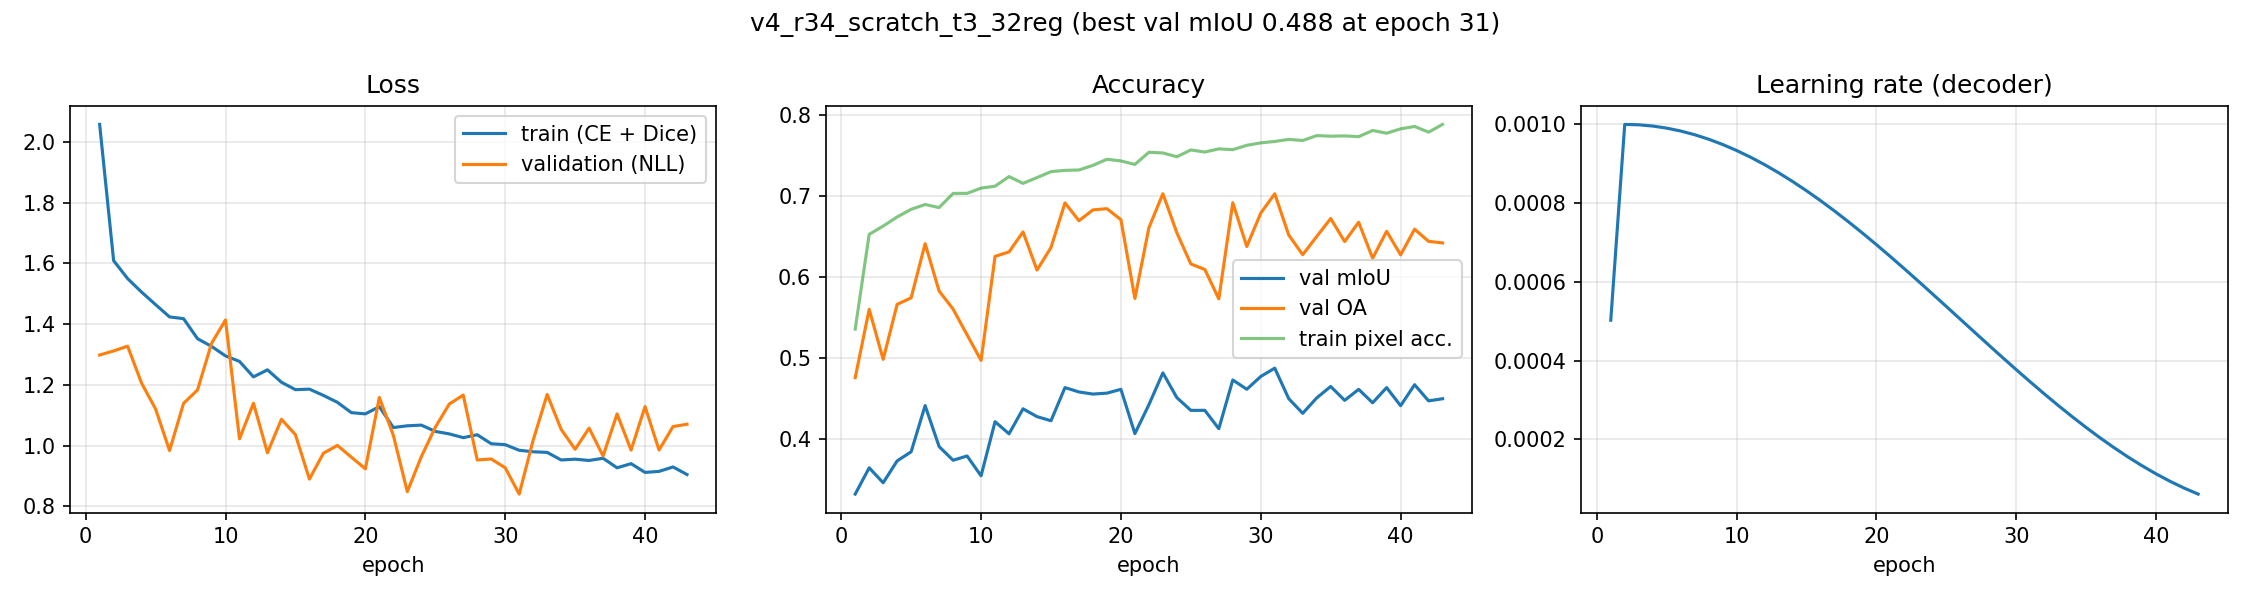

============================== v5_r50_imagenet_t3_32reg ==============================
2026-11-08 09:27:54,502 INFO v5_r50_imagenet_t3_32reg: 32 train / 4 val regions on cuda
2026-11-08 09:27:54,649 INFO rare classes (oversampled): ['bare_sparse', 'wetland']
2026-11-08 09:27:55,174 INFO model unet/resnet50 init=imagenet, input 3 months (6 channels), 32.5M parameters
2026-11-08 09:28:49,145 INFO epoch   1/50  loss 1.9479  acc 0.557 | val mIoU 0.3849 OA 0.555 NLL 1.400 * (54s)
2026-11-08 09:29:41,815 INFO epoch   2/50  loss 1.3127  acc 0.705 | val mIoU 0.3640 OA 0.525 NLL 1.610   (52s)
2026-11-08 09:30:35,642 INFO epoch   3/50  loss 1.2041  acc 0.734 | val mIoU 0.4130 OA 0.573 NLL 1.185 * (53s)
2026-11-08 09:31:28,992 INFO epoch   4/50  loss 1.0885  acc 0.754 | val mIoU 0.4361 OA 0.622 NLL 1.163 * (53s)
2026-11-08 09:32:22,463 INFO epoch   5/50  loss 1.0202  acc 0.769 | val mIoU 0.4831 OA 0.665 NLL 0.965 * (53s)
2026-11-08 09:33:15,742 INFO epoch   6/50  loss 0.9914  acc 0.773 | val mIoU

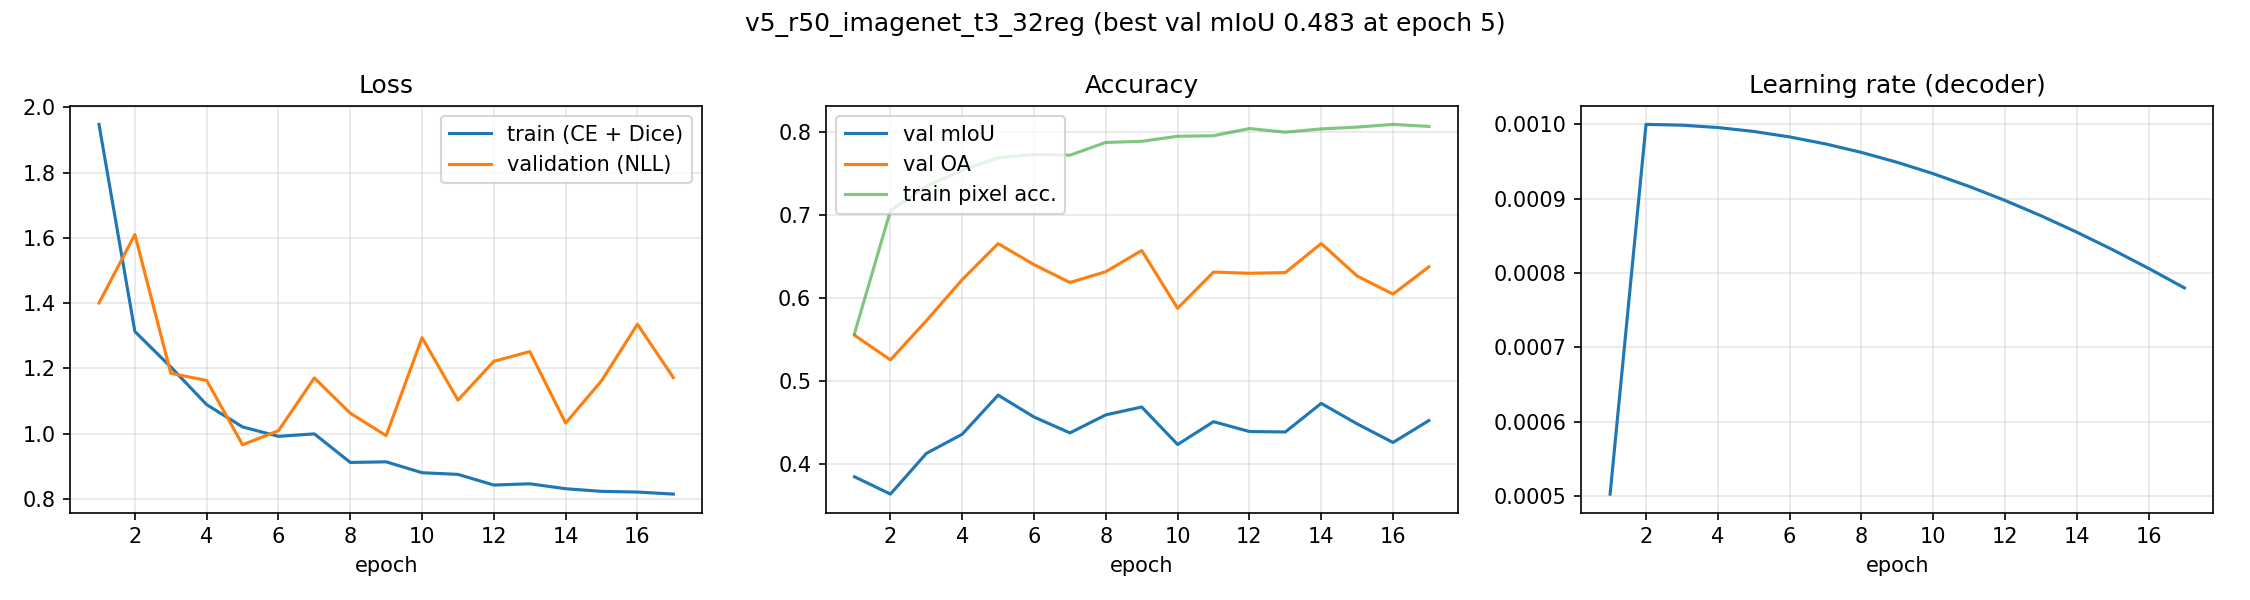

============================== v6_r50_ssl4eo_s1_t3_32reg ==============================
2026-11-08 09:43:14,720 INFO v6_r50_ssl4eo_s1_t3_32reg: 32 train / 4 val regions on cuda
2026-11-08 09:43:14,864 INFO rare classes (oversampled): ['bare_sparse', 'wetland']
Downloading: "https://hf.co/torchgeo/resnet50_sentinel1_all_moco/resolve/e79862c667853c10a709bdd77ea8ffbad0e0f1cf/resnet50_sentinel1_all_moco-906e4356.pth" to /root/.cache/torch/hub/checkpoints/resnet50_sentinel1_all_moco-906e4356.pth


100%|██████████| 90.0M/90.0M [00:01<00:00, 84.2MB/s]


2026-11-08 09:43:16,883 INFO loaded 318/265 SSL4EO-S12 encoder tensors
2026-11-08 09:43:16,927 INFO model unet/resnet50 init=ssl4eo_s1, input 3 months (6 channels), 32.5M parameters
2026-11-08 09:44:10,689 INFO epoch   1/50  loss 1.9038  acc 0.583 | val mIoU 0.3833 OA 0.547 NLL 1.223 * (54s)
2026-11-08 09:45:03,618 INFO epoch   2/50  loss 1.3381  acc 0.708 | val mIoU 0.3910 OA 0.546 NLL 1.434 * (52s)
2026-11-08 09:45:57,159 INFO epoch   3/50  loss 1.2208  acc 0.735 | val mIoU 0.3682 OA 0.513 NLL 1.450   (53s)
2026-11-08 09:46:50,794 INFO epoch   4/50  loss 1.1309  acc 0.748 | val mIoU 0.4075 OA 0.580 NLL 1.241 * (53s)
2026-11-08 09:47:44,236 INFO epoch   5/50  loss 1.0761  acc 0.760 | val mIoU 0.4227 OA 0.579 NLL 1.244 * (53s)
2026-11-08 09:48:37,821 INFO epoch   6/50  loss 1.0359  acc 0.766 | val mIoU 0.4451 OA 0.610 NLL 1.092 * (53s)
2026-11-08 09:49:31,176 INFO epoch   7/50  loss 1.0341  acc 0.764 | val mIoU 0.4340 OA 0.610 NLL 1.224   (53s)
2026-11-08 09:50:24,354 INFO epoch   8/50

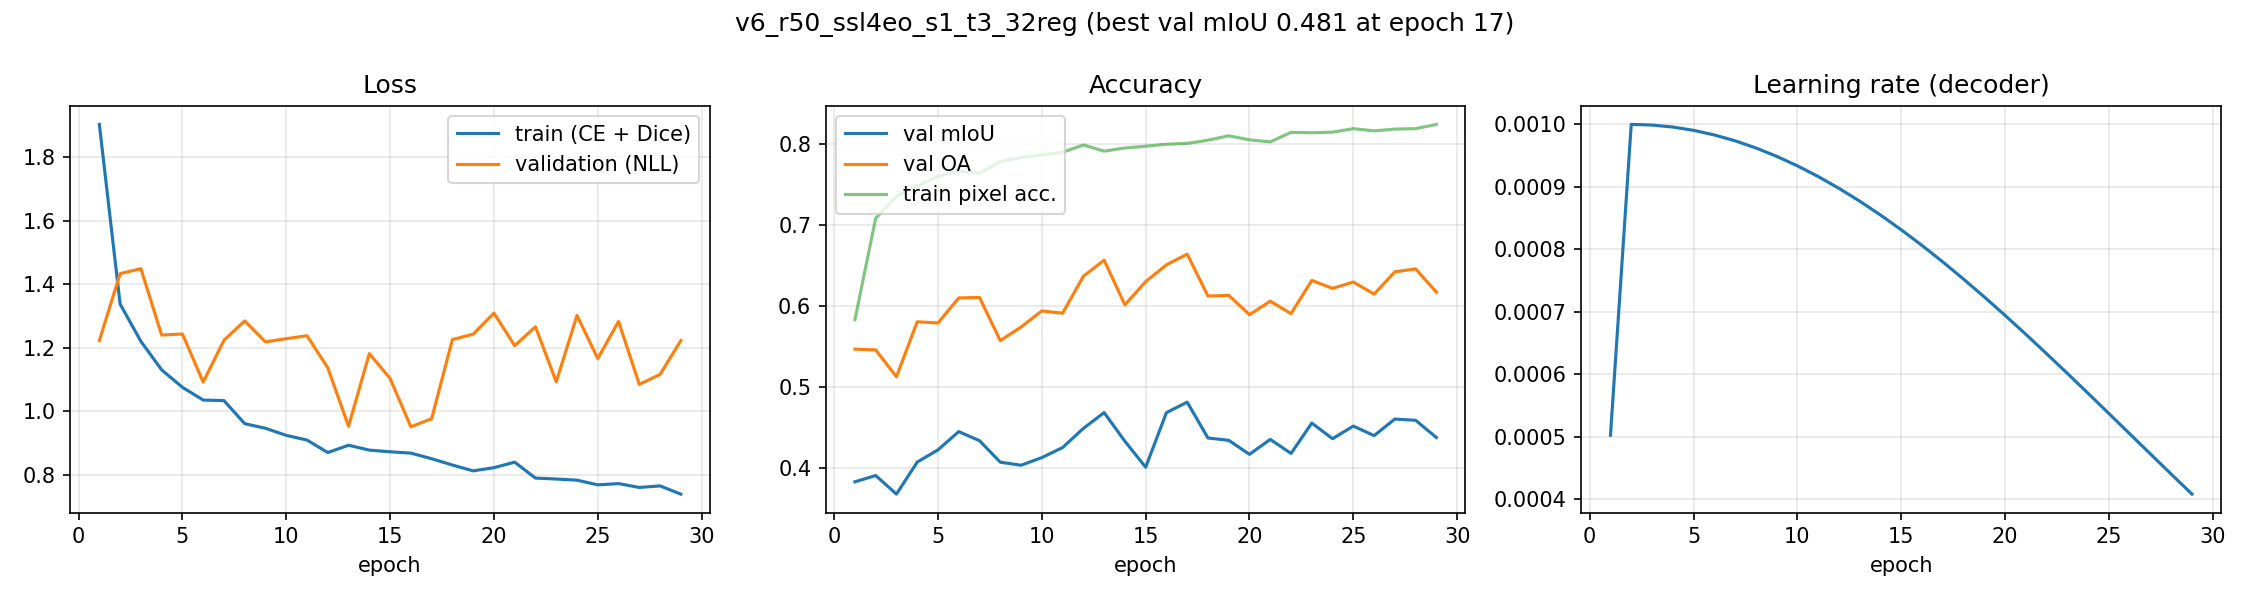

In [4]:
from IPython.display import Image, display
from s1lulc.train import load_train_config, train_variant
cfg = load_train_config()
cfg["num_workers"] = min(4, os.cpu_count())
# Round 2 (32 training regions): two single-month baselines (data-scaling comparison with
# round 1) and three 3-month-input models. TAG marks the run in all output names.
VARIANTS = ["v1_r34_scratch", "v2_r50_imagenet",
            "v4_r34_scratch_t3", "v5_r50_imagenet_t3", "v6_r50_ssl4eo_s1_t3"]
TAG = "_32reg"
import json as _json
n_train = sum(r["split"] == "train" for r in _json.loads((DATA / "meta.json").read_text())["regions"])
print("training regions in this dataset version:", n_train)
TRAIN_OUT = Path("/kaggle/working/outputs/train")
bundles = {}
for v in VARIANTS:
    name = v + TAG
    cfg["variants"][name] = cfg["variants"][v]
    print("=" * 30, name, "=" * 30)
    bundles[name] = train_variant(DATA, TRAIN_OUT, name, cfg)
    display(Image(str(TRAIN_OUT / name / "training_curves.png")))

## Evaluation on validation, test and out-of-distribution regions

In [5]:
import json, pandas as pd
from s1lulc.evaluate import evaluate_bundle, compare_variants
EVAL_OUT = Path("/kaggle/working/outputs/eval")
for variant, b in bundles.items():
    print("evaluating", variant)
    evaluate_bundle(b, DATA, EVAL_OUT / variant)
table = pd.DataFrame(compare_variants(EVAL_OUT, TRAIN_OUT))
display(table)

2026-11-08 10:09:04,392 INFO NumExpr defaulting to 4 threads.
evaluating v1_r34_scratch_32reg
2026-11-08 10:09:06,692 INFO evaluating vienna (val)
2026-11-08 10:09:12,782 INFO evaluating brittany_rural (val)
2026-11-08 10:09:17,928 INFO evaluating danube_delta (val)
2026-11-08 10:09:22,675 INFO evaluating castilla_dry (val)
2026-11-08 10:09:32,717 INFO evaluating prague (test)
2026-11-08 10:09:39,022 INFO evaluating tuscany (test)
2026-11-08 10:09:44,768 INFO evaluating sweden_forest (test)
2026-11-08 10:09:54,615 INFO evaluating cairo_nile (test_ood)
2026-11-08 10:09:59,586 INFO evaluating sao_paulo (test_ood)
2026-11-08 10:10:06,492 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-08 10:10:06,494 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as num

,variant,epochs_run,best_epoch,train_minutes,val_oa,val_miou,val_miou_smoothed,test_oa,test_miou,test_miou_smoothed,test_ood_oa,test_ood_miou,test_ood_miou_smoothed
0,v1_r34_scratch_32reg,35,23,22.2,0.6464,0.4539,0.4637,0.7391,0.4209,0.4373,0.8392,0.3044,0.3066
1,v2_r50_imagenet_32reg,33,21,27.0,0.6280,0.4592,0.4684,0.8398,0.4687,0.4767,0.8729,0.3092,0.3099
2,v4_r34_scratch_t3_32reg,43,31,30.2,0.7026,0.4876,0.4974,0.8279,0.4672,0.4786,0.8253,0.3531,0.3565
3,v5_r50_imagenet_t3_32reg,17,5,15.0,0.6654,0.4831,0.4923,0.8392,0.4629,0.4616,0.8783,0.3698,0.3747
4,v6_r50_ssl4eo_s1_t3_32reg,29,17,25.5,0.6639,0.4815,0.4905,0.8569,0.4869,0.4935,0.8888,0.3806,0.3847


## Model selection
The final model is chosen by **validation** mIoU, never by test scores, so the test results stay
an unbiased estimate.

In [6]:
best = table.sort_values("val_miou", ascending=False).iloc[0]["variant"]
print("selected model:", best)
FINAL = Path("/kaggle/working/outputs/final_bundle")
shutil.rmtree(FINAL, ignore_errors=True)
shutil.copytree(bundles[best], FINAL)
m = json.loads((EVAL_OUT / best / "metrics.json").read_text())
for s, d in m["splits"].items():
    print(f"{s:9s} OA {d['raw']['overall_accuracy']:.3f}  mIoU {d['raw']['mean_iou']:.3f}"
          f"  | smoothed mIoU {d['smoothed']['mean_iou']:.3f}")
display(pd.read_csv(EVAL_OUT / best / "per_class.csv").query("prediction == 'raw'")
        .pivot(index="class", columns="split", values=["iou", "f1"]).round(3))

selected model: v4_r34_scratch_t3_32reg
val       OA 0.703  mIoU 0.488  | smoothed mIoU 0.497
test      OA 0.828  mIoU 0.467  | smoothed mIoU 0.479
test_ood  OA 0.825  mIoU 0.353  | smoothed mIoU 0.357


iou                     f1                
split            test test_ood    val   test test_ood    val
class                                                       
bare_sparse     0.002    0.414  0.025  0.004    0.586  0.049
built_up        0.631    0.826  0.740  0.774    0.904  0.850
cropland        0.469    0.164  0.609  0.638    0.282  0.757
low_vegetation  0.446    0.116  0.267  0.616    0.208  0.422
tree_cover      0.817    0.182  0.361  0.899    0.308  0.531
water           0.896    0.768  0.812  0.945    0.869  0.896
wetland         0.010    0.001  0.598  0.020    0.002  0.748

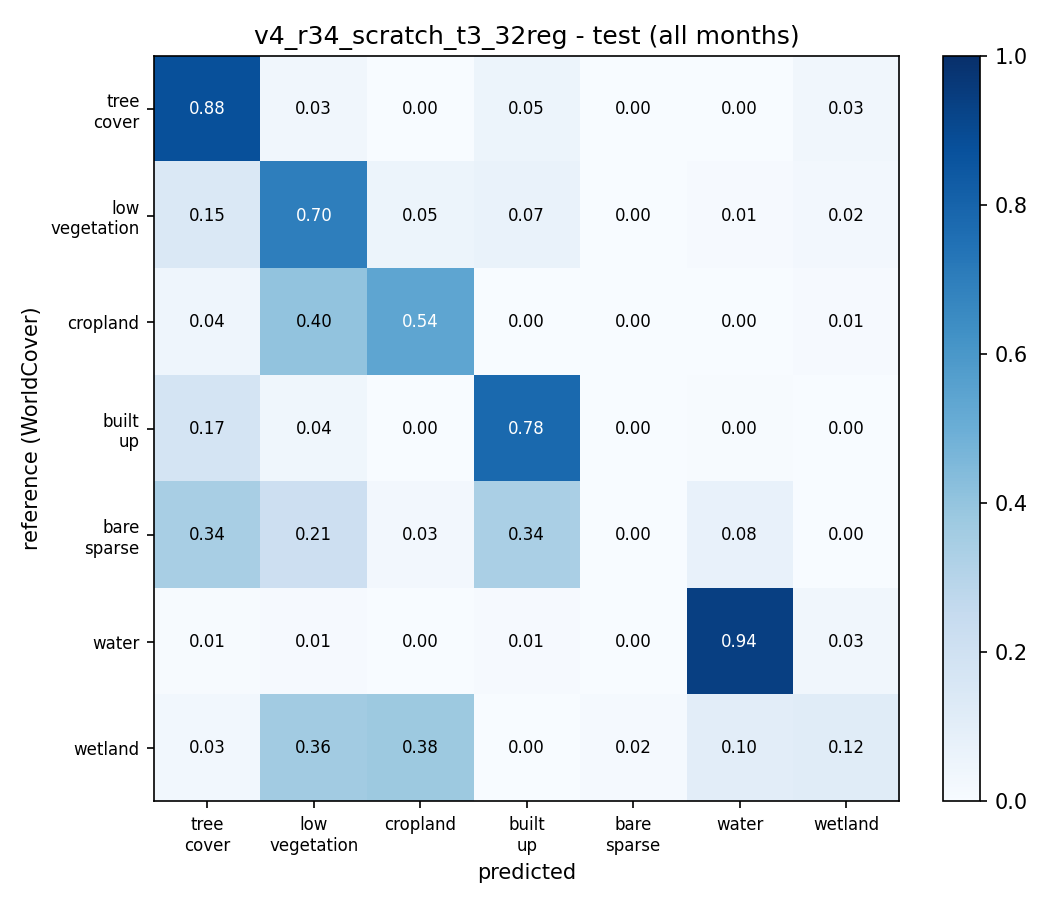

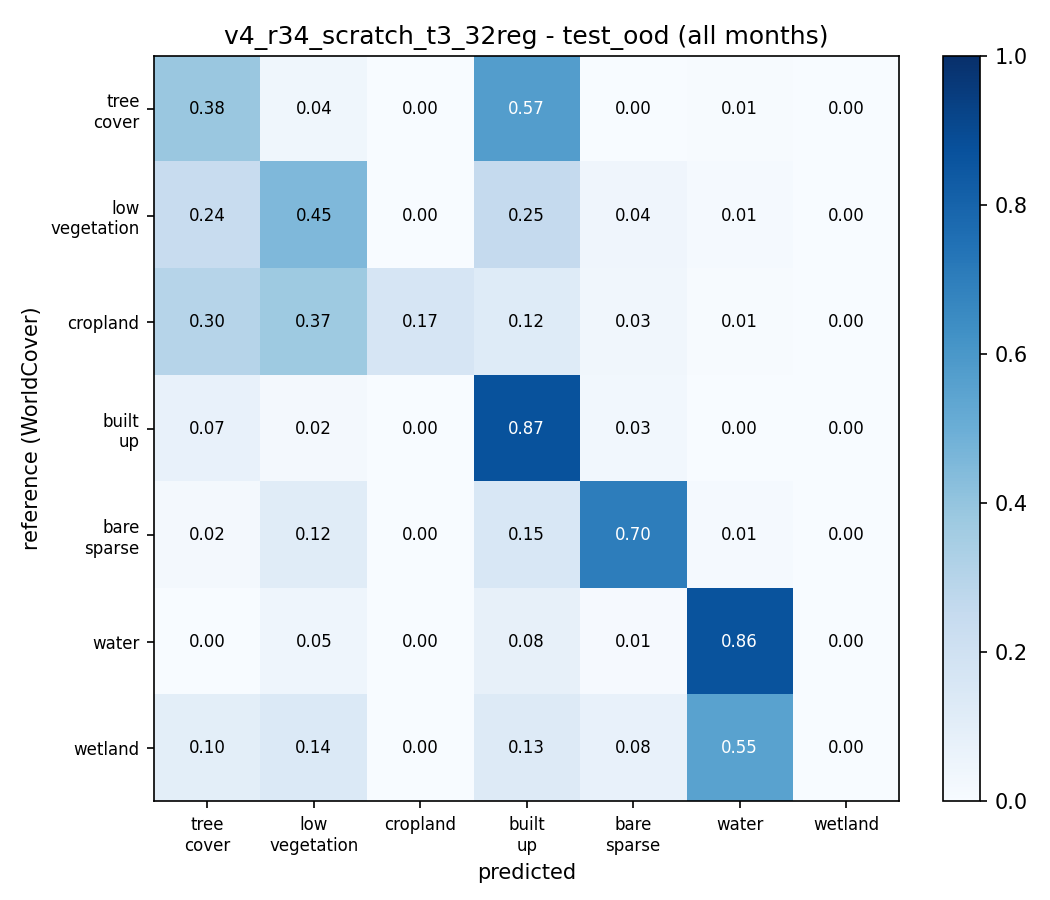

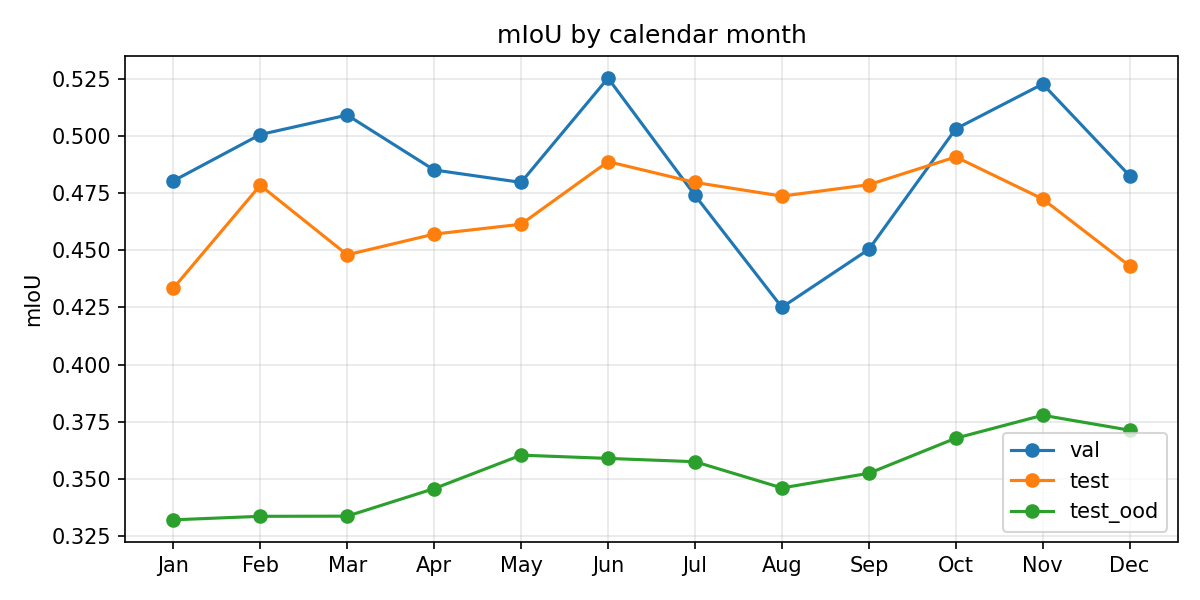

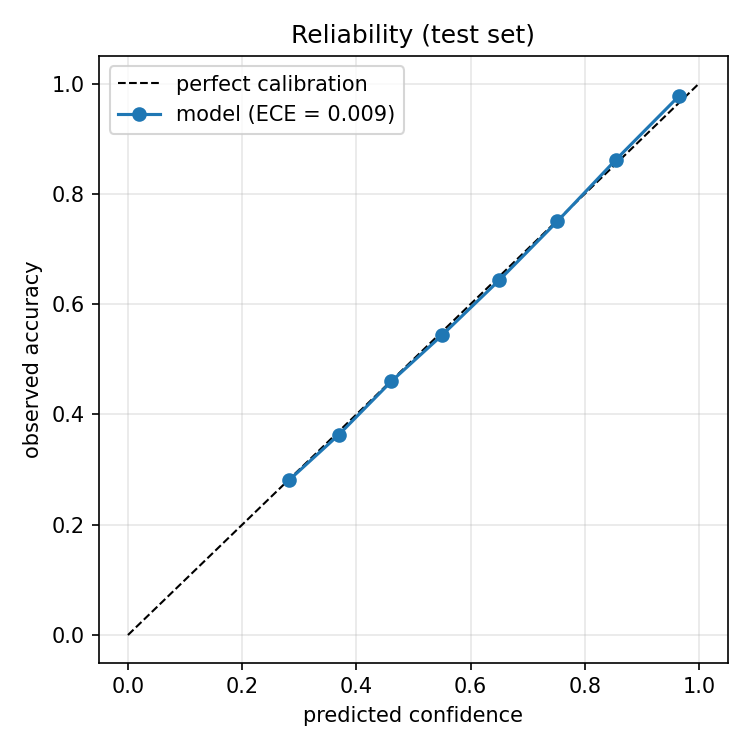

Calibration: {'ece': 0.00859675291612418, 'mean_entropy_correct': 0.21089764622350535, 'mean_entropy_wrong': 0.4166127335694101}


,month-to-month raw,month-to-month smoothed,first-to-last raw,first-to-last smoothed
tree_cover,12.47,7.07,11.92,7.55
low_vegetation,12.08,6.96,16.07,16.28
cropland,20.76,10.67,50.79,26.26
built_up,0.90,0.38,2.01,1.19
bare_sparse,0.88,0.31,22.56,0.49
water,1.18,0.89,0.75,1.12
wetland,13.21,7.96,9.12,10.56


,region,split,mae_raw_pp,mae_smoothed_pp,flicker_raw,flicker_smoothed,mae_adjusted_pp
0,vienna,val,2.010,2.023,0.241,0.134,2.606
1,brittany_rural,val,2.481,2.131,1.440,0.749,3.369
2,danube_delta,val,4.561,4.041,1.784,0.909,6.663
3,castilla_dry,val,9.304,7.919,3.077,1.742,7.408
4,prague,test,0.700,0.687,0.443,0.247,4.575
5,tuscany,test,1.864,1.670,0.667,0.310,10.790
6,sweden_forest,test,2.701,2.236,0.921,0.576,10.753
7,cairo_nile,test_ood,3.741,3.693,0.698,0.378,8.538
8,sao_paulo,test_ood,0.487,0.447,0.388,0.184,4.222


In [7]:
for f in ["confusion_test.png", "confusion_test_ood.png", "miou_per_month.png", "reliability_test.png"]:
    p = EVAL_OUT / best / f
    if p.exists():
        display(Image(str(p)))
print("Calibration:", {k: m["calibration_test"][k] for k in
      ["ece", "mean_entropy_correct", "mean_entropy_wrong"]})
nf = m["noise_floor"]
display(pd.DataFrame({"month-to-month raw": nf["raw"]["month_step_pp"],
                      "month-to-month smoothed": nf["smoothed"]["month_step_pp"],
                      "first-to-last raw": nf["raw"]["total_pp"],
                      "first-to-last smoothed": nf["smoothed"]["total_pp"]},
                     index=nf["raw"]["class_names"]).round(2))
display(pd.DataFrame(m["share_error"]).round(3))

## Package results

In [8]:
!cd /kaggle/working/outputs && rm -f ../results.zip && zip -q -r ../results.zip eval final_bundle train -x "*/last.pt"
!ls -lh /kaggle/working/results.zip

-rw-r--r-- 1 root root 609M Nov  8 10:14 /kaggle/working/results.zip
